In [10]:
import tensorflow as tf
from keras.layers import Input,Dense,Flatten
from keras.models import Sequential
import matplotlib.pyplot as plt
from keras.datasets import mnist
import numpy as np

In [11]:
(train_X, train_y), (test_X, test_y) = mnist.load_data()
#printing the shapes of the vectors
print('X_train: ' + str(train_X.shape))
print('Y_train: ' + str(train_y.shape))
print('X_test:  '  + str(test_X.shape))
print('Y_test:  '  + str(test_y.shape))

X_train: (60000, 28, 28)
Y_train: (60000,)
X_test:  (10000, 28, 28)
Y_test:  (10000,)


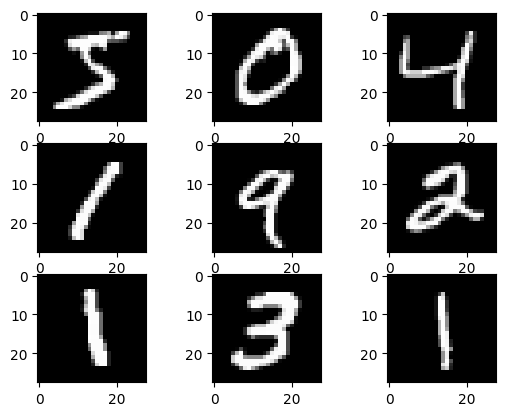

In [12]:
train_X = train_X / 255
test_X = test_X / 255
#Displaying the n first digits in the datset
for i in range(9):
  plt.subplot(330 + 1 + i) #rows col pos
  plt.imshow(train_X[i], cmap=plt.get_cmap('gray'))
plt.show()

In [42]:
model = Sequential(
    [   Input((28,28)),
        Flatten(),
        Dense(128, activation="relu", name="layer1"),
        Dense(128, activation="relu", name="layer2"),
        # Dense(128, activation='relu', name='layer3'),
        Dense(10, activation="softmax"),
    ]
)

In [43]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [44]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer1 (Dense)                  │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,282 (462.04 KB)

 Trainable params: 118,282 (462.04 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
model.fit(x=train_X, y=train_y, epochs=25, validation_split=0.2)

Epoch 1/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9249 - loss: 0.2562 - val_accuracy: 0.9636 - val_loss: 0.1215
Epoch 2/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9693 - loss: 0.1040 - val_accuracy: 0.9699 - val_loss: 0.0999
Epoch 3/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9785 - loss: 0.0703 - val_accuracy: 0.9728 - val_loss: 0.0942
Epoch 4/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9840 - loss: 0.0507 - val_accuracy: 0.9729 - val_loss: 0.0949
Epoch 5/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9861 - loss: 0.0414 - val_accuracy: 0.9737 - val_loss: 0.0968
Epoch 6/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9887 - loss: 0.0341 - val_accuracy: 0.9728 - val_loss: 0.1056
Epoch 7/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9915 - loss: 0.0263 - val_accuracy: 0.9721 - val_loss: 0.1144
Epoch 8/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9917 - loss: 0.0247 - 

In [46]:
model.evaluate(x=test_X,y=test_y)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9784 - loss: 0.1221


[0.122128427028656, 0.9783999919891357]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
5


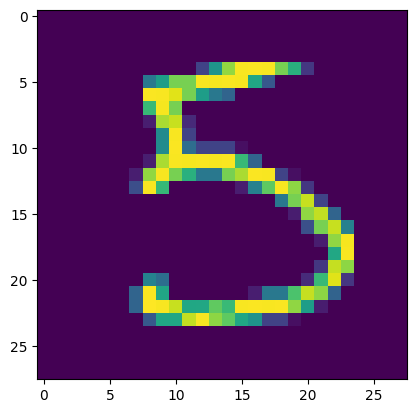

In [47]:
print(np.argmax(model.predict(np.array([test_X[15]]))))
plt.imshow(test_X[15])